## **Decision Tree**

### **Classifier machine learning algorithm to predict the  safety of the car<br>(unacceptable,acceptable,good,very good) with Python**

### **Imoprt Libraries**

In [91]:
import numpy as np
import pandas as  pd 

In [92]:
df = pd.read_csv(r"C:\Users\LENOVO\Downloads\car_evaluation.csv",header=None)

In [93]:
df.head()

,0,1,2,3,4,5,6
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


## **EDA**

In [94]:
df.shape

(1728, 7)

## **Rename column names**

In [95]:
col_names = ['buying','maint','doors','person','lug_boot','safety','class']
df.columns = col_names
col_names

['buying', 'maint', 'doors', 'person', 'lug_boot', 'safety', 'class']

In [96]:
df.head()

,buying,maint,doors,person,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [97]:
df.tail()

,buying,maint,doors,person,lug_boot,safety,class
1723,low,low,5more,more,med,med,good
1724,low,low,5more,more,med,high,vgood
1725,low,low,5more,more,big,low,unacc
1726,low,low,5more,more,big,med,good
1727,low,low,5more,more,big,high,vgood


In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   person    1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


## **Frequency distribution of values in variables**

In [99]:
col_names = ['buying','maint','doors','person','lug_boot','safety','class']
for col in col_names:
    print(df[col].value_counts())

buying
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64
maint
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64
doors
2        432
3        432
4        432
5more    432
Name: count, dtype: int64
person
2       576
4       576
more    576
Name: count, dtype: int64
lug_boot
small    576
med      576
big      576
Name: count, dtype: int64
safety
low     576
med     576
high    576
Name: count, dtype: int64
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


In [100]:
# There are 7 variable in a dataset 
# class is our target variable

In [101]:
df['class'].value_counts()

class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

## **Declear Feature vector and target variable.**

In [102]:
X = df.drop('class',axis=1)
Y = df['class']

In [103]:
X.head()

,buying,maint,doors,person,lug_boot,safety
0,vhigh,vhigh,2,2,small,low
1,vhigh,vhigh,2,2,small,med
2,vhigh,vhigh,2,2,small,high
3,vhigh,vhigh,2,2,med,low
4,vhigh,vhigh,2,2,med,med


In [104]:
Y.value_counts()

class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

## **Split data into training and test set**

In [105]:
from sklearn.model_selection import train_test_split

In [106]:
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.33,random_state=42)

In [107]:
x_train

,buying,maint,doors,person,lug_boot,safety
48,vhigh,vhigh,3,more,med,low
468,high,vhigh,3,4,small,low
155,vhigh,high,3,more,small,high
1721,low,low,5more,more,small,high
1208,med,low,2,more,small,high
...,...,...,...,...,...,...
1130,med,med,3,more,med,high
1294,med,low,5more,more,big,med
860,high,low,5more,more,med,high
1459,low,high,4,2,small,med


In [108]:
# Check the shape of x_train and x_test 
x_train.shape,x_test.shape

((1157, 6), (571, 6))

In [109]:
# Check the shape of y_train and y_test 
y_train.shape,y_test.shape

((1157,), (571,))

## **Feature Engineering**

In [110]:
# Check data type of x_train 
x_train.dtypes

buying      object
maint       object
doors       object
person      object
lug_boot    object
safety      object
dtype: object

## **Encode categorical variables**

In [111]:
from sklearn.preprocessing import LabelEncoder

In [112]:
x_train.head()

,buying,maint,doors,person,lug_boot,safety
48,vhigh,vhigh,3,more,med,low
468,high,vhigh,3,4,small,low
155,vhigh,high,3,more,small,high
1721,low,low,5more,more,small,high
1208,med,low,2,more,small,high


In [113]:
# Import category encoders
import category_encoders as ce

In [114]:
# encode variables with ordinal encoding
encoder = ce.OrdinalEncoder(cols=['buying','maint','doors','person','lug_boot','safety'])

In [115]:
## OrdinalEncoder from category converts categorical featutes to numerical values
# While preserving ordinal relationships.
# oridnal low --> med ---> high

In [116]:
x_train = encoder.fit_transform(x_train)

In [117]:
x_test = encoder.transform(x_test)

In [118]:
x_test.head()

,buying,maint,doors,person,lug_boot,safety
599,2,2,4,3,1,2
1201,4,3,3,2,1,3
628,2,2,2,3,3,3
1498,3,2,2,2,1,3
1263,4,3,4,1,1,1


In [119]:
x_train.dtypes

buying      int64
maint       int64
doors       int64
person      int64
lug_boot    int64
safety      int64
dtype: object

In [120]:
y_train.head()

48      unacc
468     unacc
155     unacc
1721     good
1208    unacc
Name: class, dtype: object

## **Decision Tree Classifier**

In [121]:
from sklearn.tree import DecisionTreeClassifier

In [122]:
clf_gini =DecisionTreeClassifier(criterion='gini',max_depth=3,random_state=0)
# Creation = 'gini': Uses Gini impurity to measure split quality
# other alternative is 'entropy'
# max_depth = 3 : Limites tree depth to prevent overfitting.
# random_state = 0: Ensures reproducible results.
# Random_state why use 0 ?
## Ensures anyone running your code gets identical results


In [123]:
# Fit the model 
clf_gini.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current nod

## **Predict the test set results with creation gini index**

In [124]:
y_pred_gini = clf_gini.predict(x_test)

## **Check accuracy score with creation gini index**

In [125]:
y_pred_gini[:5]

array(['unacc', 'acc', 'unacc', 'acc', 'unacc'], dtype=object)

## **Check accuracy score with creation gini index**

In [126]:
y_pred_gini[:10]

array(['unacc', 'acc', 'unacc', 'acc', 'unacc', 'acc', 'unacc', 'unacc',
       'acc', 'unacc'], dtype=object)

In [127]:
from sklearn.metrics import accuracy_score
print('Model accuracy with gini index: {0:0.4f}'.format(accuracy_score(y_test,y_pred_gini)))

Model accuracy with gini index: 0.8021


## **Check for overfitting and underfitting**

In [128]:
# Print the scores on training and test set
print('Training set score: {:.4f}'.format(clf_gini.score(x_train,y_train)))
print('Test set score: {:.4f}'.format(clf_gini.score(x_test,y_test)))

Training set score: 0.7865
Test set score: 0.8021


## **Visualize decision-trees**

[Text(0.4, 0.875, 'x[5] <= 1.5\ngini = 0.455\nsamples = 1157\nvalue = [255, 49, 813, 40]'),
 Text(0.2, 0.625, 'gini = 0.0\nsamples = 386\nvalue = [0, 0, 386, 0]'),
 Text(0.30000000000000004, 0.75, 'True  '),
 Text(0.6, 0.625, 'x[3] <= 2.5\ngini = 0.577\nsamples = 771\nvalue = [255, 49, 427, 40]'),
 Text(0.5, 0.75, '  False'),
 Text(0.4, 0.375, 'x[0] <= 2.5\ngini = 0.631\nsamples = 525\nvalue = [255.0, 49.0, 181.0, 40.0]'),
 Text(0.2, 0.125, 'gini = 0.496\nsamples = 271\nvalue = [124, 0, 147, 0]'),
 Text(0.6, 0.125, 'gini = 0.654\nsamples = 254\nvalue = [131, 49, 34, 40]'),
 Text(0.8, 0.375, 'gini = 0.0\nsamples = 246\nvalue = [0, 0, 246, 0]')]

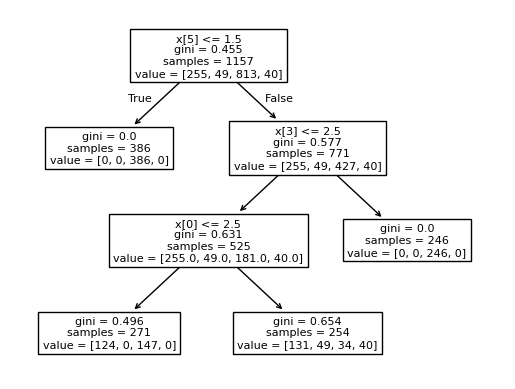

In [129]:
import matplotlib.pyplot as plt
from sklearn import tree
tree.plot_tree(clf_gini.fit(x_train,y_train))

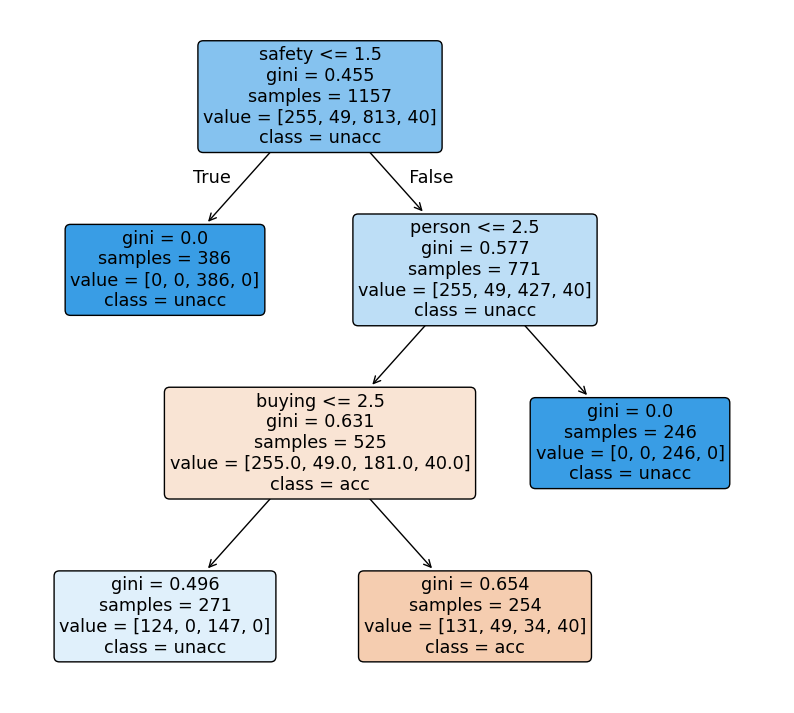

In [139]:
import matplotlib.pyplot as plt 
from sklearn.tree import DecisionTreeClassifier , plot_tree

plt.figure(figsize=(10,9))
plot_tree(clf_gini,feature_names=X.columns,class_names=clf_gini.classes_,filled= True,rounded=True)
plt.show()

## **Decsion Tree Classifier with criterion entropy**

In [131]:
clf_en = DecisionTreeClassifier(criterion='entropy',max_depth=3,random_state=0)
# fit the model 
clf_en.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

In [132]:
# Enatropy vs Gini 
# Enatropy : Uses log(math) -> Slightly slower but more sensitive
# Gini: Simpler/Faster -> usally similer results
# Try both and compare accuaracy

## **Predict the Test set results with creation enatropy**

In [133]:
y_pred_en = clf_en.predict(x_test)

## **Check accuracy score with creation entropy**

In [134]:
from sklearn.metrics import accuracy_score
print("Model Accuaracy Score With Creation Enatropy: {0:0.4f}".format(accuracy_score(y_test,y_pred_en)))

Model Accuaracy Score With Creation Enatropy: 0.8021


## **Compare the train-set and test-set accuracy**

In [135]:
y_pred_train_en = clf_en.predict(x_train)
y_pred_train_en

array(['unacc', 'unacc', 'unacc', ..., 'unacc', 'unacc', 'acc'],
      shape=(1157,), dtype=object)

In [136]:
print('Testing-set accuracy score: {0:0.4f}:'.format(accuracy_score(y_train,y_pred_train_en)))

Testing-set accuracy score: 0.7865:


## **Check for Overfitting and Underfitting**

In [137]:
# Print the scores on training and test set
print('Training set score: {0:0.4f}'.format(clf_en.score(x_train,y_train)))
print('Test Set Score: {0:0.4f}'.format(clf_en.score(x_test,y_test)))

Training set score: 0.7865
Test Set Score: 0.8021


## **Confusion Matrix**

In [140]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred_en)
print('Confusion Matrix:\n',cm)

Confusion Matrix:
 [[ 73   0  56   0]
 [ 20   0   0   0]
 [ 12   0 385   0]
 [ 25   0   0   0]]


## **Classification Report**

In [144]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_en))

              precision    recall  f1-score   support

         acc       0.56      0.57      0.56       129
        good       0.00      0.00      0.00        20
       unacc       0.87      0.97      0.92       397
       vgood       0.00      0.00      0.00        25

    accuracy                           0.80       571
   macro avg       0.36      0.38      0.37       571
weighted avg       0.73      0.80      0.77       571



c:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(